1. Import the libraries

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

2. Importing the data

In [23]:
df = pd.read_csv("f1_performance_analysis_sample_720.csv")

In [3]:
df.head()

,Season,Round,Race,Circuit,Country,Driver,Constructor,Grid_Position,Qualifying_Position,Finish_Position,...,Laps_Completed,Fastest_Lap_Time_sec,Pit_Stops,Avg_Pit_Stop_Duration_sec,Status,Positions_Gained,Qualifying_Time_sec,Is_DNF,Is_Podium,Is_Win
0,2022,1,Bahrain GP,Bahrain International Circuit,Bahrain,Lewis Hamilton,Mercedes,1,3,1,...,50,88.079,0,0.000,Finished,0.0,88.632,False,True,True
1,2022,1,Bahrain GP,Bahrain International Circuit,Bahrain,Sergio Perez,Red Bull,2,1,3,...,56,89.706,2,24.855,Finished,-1.0,88.298,False,True,False
2,2022,1,Bahrain GP,Bahrain International Circuit,Bahrain,Max Verstappen,Red Bull,3,3,2,...,57,88.588,3,22.036,Finished,1.0,88.512,False,True,False
3,2022,1,Bahrain GP,Bahrain International Circuit,Bahrain,George Russell,Mercedes,4,3,4,...,59,88.568,0,0.000,Finished,0.0,88.817,False,False,False
4,2022,1,Bahrain GP,Bahrain International Circuit,Bahrain,Charles Leclerc,Ferrari,5,6,DNF,...,44,87.960,2,26.789,Mechanical,NaN,89.058,True,False,False


In [5]:
df.shape

(720, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Season                     720 non-null    int64  
 1   Round                      720 non-null    int64  
 2   Race                       720 non-null    str    
 3   Circuit                    720 non-null    str    
 4   Country                    720 non-null    str    
 5   Driver                     720 non-null    str    
 6   Constructor                720 non-null    str    
 7   Grid_Position              720 non-null    int64  
 8   Qualifying_Position        720 non-null    int64  
 9   Finish_Position            720 non-null    str    
 10  Points                     720 non-null    float64
 11  Laps_Completed             720 non-null    int64  
 12  Fastest_Lap_Time_sec       720 non-null    float64
 13  Pit_Stops                  720 non-null    int64  
 14  Avg_P

In [7]:
df.describe()

,Season,Round,Grid_Position,Qualifying_Position,Points,Laps_Completed,Fastest_Lap_Time_sec,Pit_Stops,Avg_Pit_Stop_Duration_sec,Positions_Gained,Qualifying_Time_sec
count,720.000000,720.000000,720.00000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,683.000000,720.000000
mean,2023.000000,6.500000,10.50000,10.416667,5.743056,53.750000,88.525499,1.305556,17.395975,0.245974,90.279267
std,0.817064,3.454452,5.77029,5.764864,8.306495,7.364445,0.799173,1.086507,10.522702,3.404042,1.283857
min,2022.000000,1.000000,1.00000,1.000000,0.000000,5.000000,86.141000,0.000000,0.000000,-13.000000,87.692000
25%,2022.000000,3.750000,5.75000,6.000000,0.000000,52.000000,88.027750,0.000000,0.000000,-2.000000,89.209000
50%,2023.000000,6.500000,10.50000,10.000000,1.000000,55.000000,88.511500,1.000000,22.589000,0.000000,90.288000
75%,2024.000000,9.250000,15.25000,15.000000,10.000000,58.000000,89.026000,2.000000,24.487250,2.000000,91.391750
max,2024.000000,12.000000,20.00000,20.000000,25.000000,60.000000,91.107000,4.000000,30.493000,12.000000,92.771000


Part - 2 
Data Cleaning

In [8]:
df['Finish_Position_Num'] = pd.to_numeric(
    df['Finish_Position'],
    errors='coerce'
)

Part - 3 Data Cleaning

In [10]:
df['Position_Gained'] = df['Grid_Position'] - df['Finish_Position_Num']
print(df['Position_Gained'])

0      0.0
1     -1.0
2      1.0
3      0.0
4      NaN
      ... 
715    4.0
716    0.0
717   -2.0
718   -1.0
719    NaN
Name: Position_Gained, Length: 720, dtype: float64


Part - 4 
Data Analysis

Task - 1 
High Scoring Driver

In [11]:
driver_points = df.groupby('Driver')['Points'].sum().sort_values(ascending=False)

print(driver_points)
print("Top Driver:", driver_points.idxmax())
print("Total Points:", driver_points.max())

Driver
Max Verstappen      594.0
Carlos Sainz        542.0
Sergio Perez        503.0
Charles Leclerc     492.0
Lewis Hamilton      427.0
George Russell      316.0
Oscar Piastri       273.0
Lando Norris        234.0
Fernando Alonso     215.0
Pierre Gasly        167.0
Esteban Ocon        115.0
Nico Hulkenberg      58.0
Lance Stroll         49.0
Alex Albon           41.0
Valtteri Bottas      36.0
Daniel Ricciardo     34.0
Yuki Tsunoda         22.0
Logan Sargeant       17.0
Kevin Magnussen       0.0
Zhou Guanyu           0.0
Name: Points, dtype: float64
Top Driver: Max Verstappen
Total Points: 594.0


Task - 2 Best Performing Driver

In [12]:
wins = df.groupby('Driver')['Is_Win'].sum().sort_values(ascending=False)

print(wins)

Driver
Charles Leclerc     14
Sergio Perez        14
Max Verstappen      12
Carlos Sainz        11
Lewis Hamilton       9
Lando Norris         5
Oscar Piastri        5
George Russell       3
Pierre Gasly         2
Esteban Ocon         1
Fernando Alonso      1
Alex Albon           0
Daniel Ricciardo     0
Logan Sargeant       0
Kevin Magnussen      0
Lance Stroll         0
Nico Hulkenberg      0
Valtteri Bottas      0
Yuki Tsunoda         0
Zhou Guanyu          0
Name: Is_Win, dtype: int64


Task - 3 Best Performing Constructor

In [13]:
constructor_points = (
    df.groupby('Constructor')['Points']
      .sum()
      .sort_values(ascending=False)
)

print(constructor_points)

Constructor
Red Bull        1097.0
Ferrari         1034.0
Mercedes         743.0
McLaren          507.0
Alpine           282.0
Aston Martin     264.0
Haas              58.0
Williams          58.0
RB                56.0
Sauber            36.0
Name: Points, dtype: float64


In [14]:
constructor_wins = df.groupby('Constructor')['Is_Win'].sum()
constructor_podiums = df.groupby('Constructor')['Is_Podium'].sum()

Task - 4 Constructor Performance Analysis

In [15]:
constructor_analysis = df.groupby('Constructor').agg(
    Total_Points=('Points', 'sum'),
    Wins=('Is_Win', 'sum'),
    Podiums=('Is_Podium', 'sum'),
    DNFs=('Is_DNF', 'sum'),
    Avg_Finish=('Finish_Position_Num', 'mean'),
    Avg_Qualifying=('Qualifying_Position', 'mean')
).reset_index()

print(constructor_analysis)

    Constructor  Total_Points  Wins  Podiums  DNFs  Avg_Finish  Avg_Qualifying
0        Alpine         282.0     3        6     3   10.246377       11.444444
1  Aston Martin         264.0     1        5     4   10.205882       10.513889
2       Ferrari        1034.0    25       38     4    4.102941        4.611111
3          Haas          58.0     0        0     6   15.030303       15.708333
4       McLaren         507.0    10       16     3    7.840580        7.222222
5      Mercedes         743.0    12       22     3    5.695652        4.736111
6            RB          56.0     0        0     2   14.871429       15.277778
7      Red Bull        1097.0    26       41     2    3.742857        2.916667
8        Sauber          36.0     0        1     4   16.426471       17.013889
9      Williams          58.0     0        0     6   14.303030       14.722222


Task - 5 Season Performance Analysis

In [16]:
season_points = df.groupby('Season')['Points'].sum()

print(season_points)

Season
2022    1525.0
2023    1264.0
2024    1346.0
Name: Points, dtype: float64


Task - 6 Race By Race Analysis

In [17]:
race_points = df.groupby(
    ['Season', 'Round', 'Race']
)['Points'].sum().reset_index()

print(race_points)

    Season  Round               Race  Points
0     2022      1         Bahrain GP    87.0
1     2022      2   Saudi Arabian GP   112.0
2     2022      3      Australian GP   116.0
3     2022      4        Japanese GP   120.0
4     2022      5         Chinese GP   114.0
5     2022      6           Miami GP   166.0
6     2022      7  Emilia-Romagna GP   148.0
7     2022      8          Monaco GP   138.0
8     2022      9        Canadian GP   146.0
9     2022     10         Spanish GP   100.0
10    2022     11        Austrian GP   159.0
11    2022     12         British GP   119.0
12    2023      1         Bahrain GP   103.0
13    2023      2   Saudi Arabian GP   128.0
14    2023      3      Australian GP   107.0
15    2023      4        Japanese GP    92.0
16    2023      5         Chinese GP   100.0
17    2023      6           Miami GP   106.0
18    2023      7  Emilia-Romagna GP    91.0
19    2023      8          Monaco GP   113.0
20    2023      9        Canadian GP    85.0
21    2023

Task - 7 Quality Vs Race Perfromance

In [18]:
df[['Driver',
    'Qualifying_Position',
    'Grid_Position',
    'Finish_Position_Num',
    'Points']]

,Driver,Qualifying_Position,Grid_Position,Finish_Position_Num,Points
0,Lewis Hamilton,3,1,1.0,25.0
1,Sergio Perez,1,2,3.0,15.0
2,Max Verstappen,3,3,2.0,18.0
3,George Russell,3,4,4.0,12.0
4,Charles Leclerc,6,5,NaN,0.0
...,...,...,...,...,...
715,Zhou Guanyu,18,16,12.0,0.0
716,Valtteri Bottas,19,17,17.0,0.0
717,Yuki Tsunoda,17,18,20.0,0.0
718,Kevin Magnussen,17,19,20.0,0.0


Task - 8 Pitstop Analysis

In [19]:
pit_analysis = df.groupby('Pit_Stops').agg(
    Average_Points=('Points', 'mean'),
    Average_Finish=('Finish_Position_Num', 'mean'),
    Average_Pit_Duration=('Avg_Pit_Stop_Duration_sec', 'mean')
).reset_index()

print(pit_analysis)

   Pit_Stops  Average_Points  Average_Finish  Average_Pit_Duration
0          0        5.138298       10.594444              0.000000
1          1        5.565737       10.337553             23.508175
2          2        6.299465        9.649718             23.565289
3          3        5.327869       10.736842             23.441426
4          4        8.151515        9.156250             23.876182


Part - 5

Data Visualization

Chart - 1

Bar chart - Points by constructor

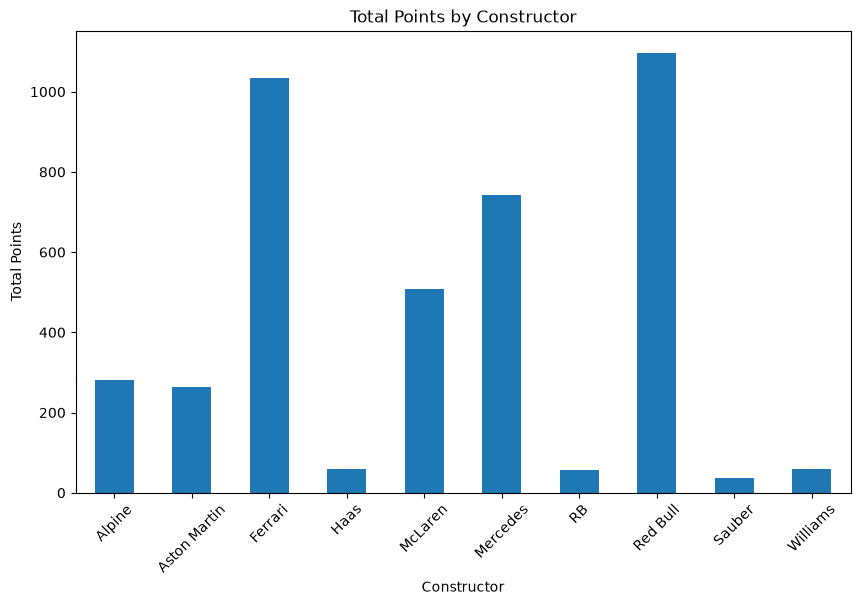

In [24]:
constructor_points = df.groupby('Constructor')['Points'].sum()

constructor_points.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Total Points by Constructor')
plt.xlabel('Constructor')
plt.ylabel('Total Points')
plt.xticks(rotation=45)
plt.show()

Chart - 2


Bar chart : Top Drivers by point

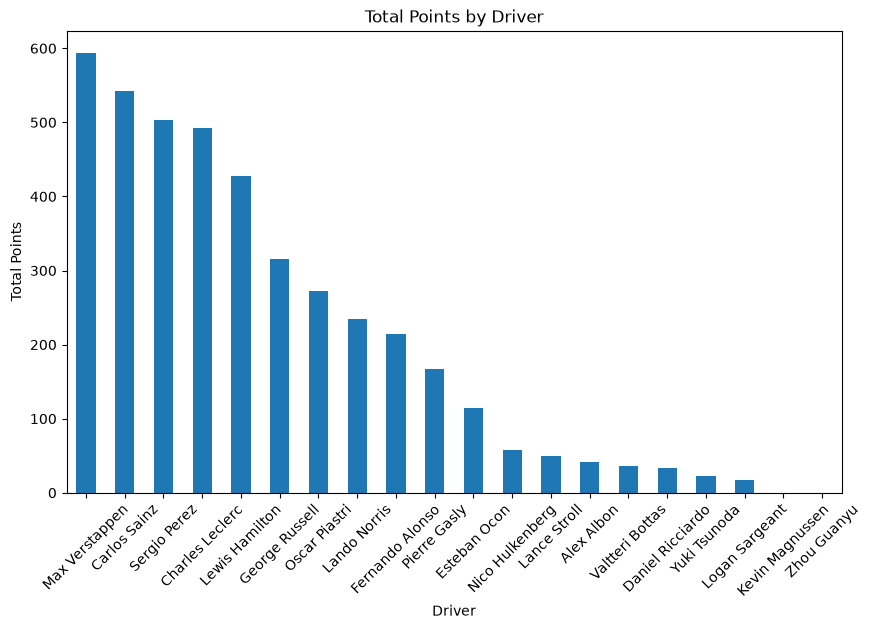

In [25]:
driver_points = (
    df.groupby('Driver')['Points']
      .sum()
      .sort_values(ascending=False)
)

driver_points.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Total Points by Driver')
plt.xlabel('Driver')
plt.ylabel('Total Points')
plt.xticks(rotation=45)
plt.show()

Chart - 3

Pie Chart - Constructor Points Contribution

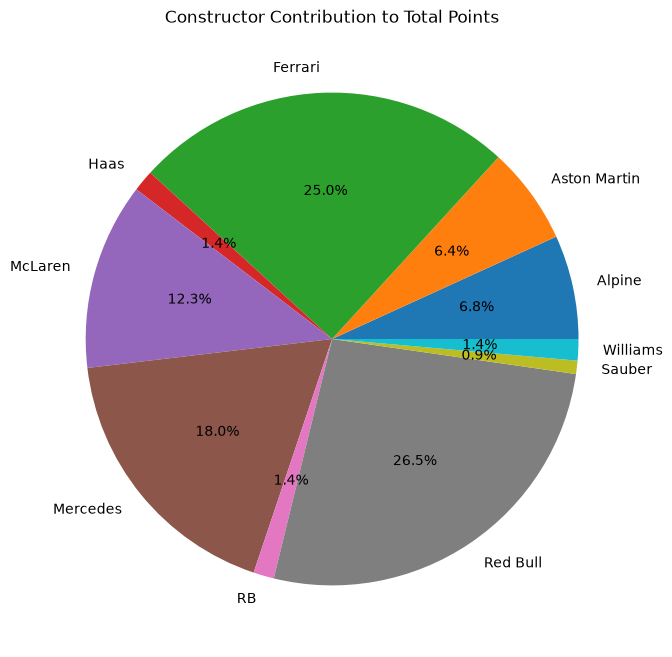

In [26]:
constructor_points.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(8, 8)
)

plt.title('Constructor Contribution to Total Points')
plt.ylabel('')
plt.show()

Chart - 4

Line Chart - Season Performance

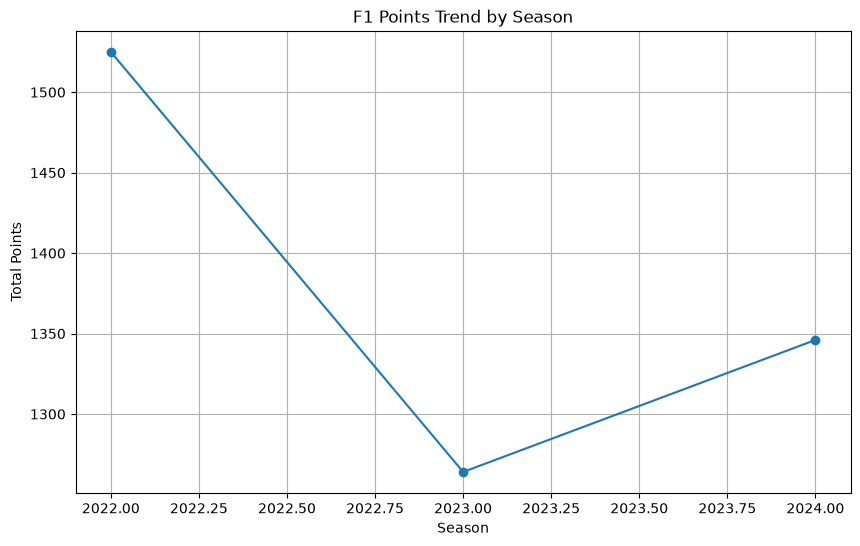

In [27]:
season_points = df.groupby('Season')['Points'].sum()

season_points.plot(
    kind='line',
    marker='o',
    figsize=(10, 6)
)

plt.title('F1 Points Trend by Season')
plt.xlabel('Season')
plt.ylabel('Total Points')
plt.grid()
plt.show()

Chart - 5

DNF Analysis - A useful F1 - specific visulaization is DNF by Constructor

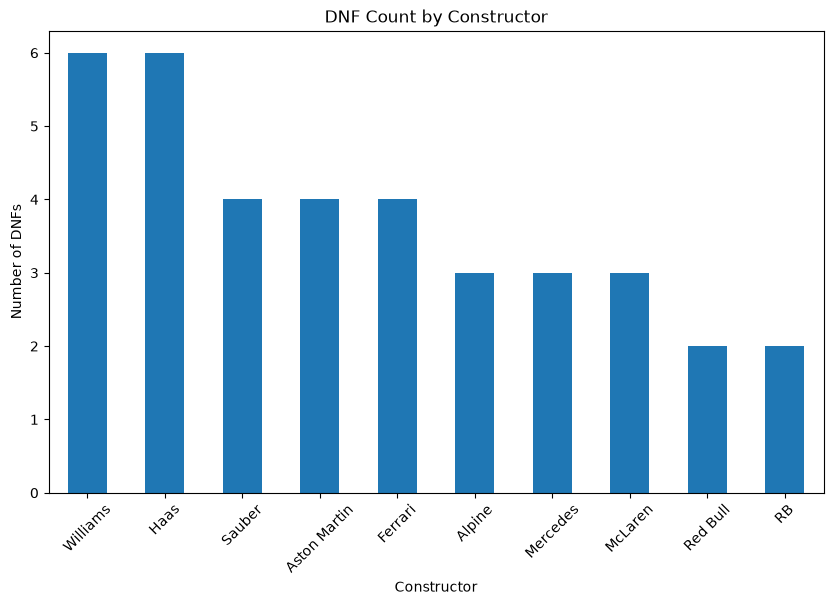

In [28]:
dnfs = df.groupby('Constructor')['Is_DNF'].sum().sort_values(ascending=False)

dnfs.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('DNF Count by Constructor')
plt.xlabel('Constructor')
plt.ylabel('Number of DNFs')
plt.xticks(rotation=45)
plt.show()